## STOR 893 Homework 3

Please see the homework assignment for details on what to implement. Starter code, including the 20 problems to test your code against, is included below.

In [4]:
import sys
import numpy as np
# Add S2MPJ and the python_problems subfolder to your path if it is not already configured
sys.path.append(r'C:\Users\woody\OneDrive\바탕 화면\FA26\STOR893\HW1\S2MPJ')
sys.path.append(r'C:\Users\woody\OneDrive\바탕 화면\FA26\STOR893\HW1\S2MPJ/python_problems')

In [2]:
#List of problems
problist = ['AVION2','BT11','CONCON','DALLASS','DECONVC','DEGENLPA','GOULDQP1','HONG','HS107','HS111','LINSPANH','LOTSCHD','MCONCON','MWRIGHT','PORTFL1','PORTFL2','SPANHYD','STREGNE','TARGUS','YORKNET']

In [5]:
import importlib

#Using importlib so we can use the problems as saved in problist
prob_index = 0
problem_name = problist[prob_index]

problem_module = importlib.import_module(problem_name)
problem_class = getattr(problem_module, problem_name)

#Initialize the problem as prob
prob = problem_class()
x0 = prob.x0
#Number of variables, number of constraints (m should = neq for equality constrained problems)
print(prob.n,prob.m,prob.neq)
epsilong = 1e-4
epsilonc = 1e-6
#Suggested settings, feel free to change as needed
maxouterit = 25
maxinnergradevals = 1000

49 15 15


In [ ]:
#Some other useful commands:

# Evaluate function, gradient and Hessian at x
# f, g, H = prob.fgHx(x)

# Evaluate constraints at x (returns vector c(x))
# cx = prob.cx(x)
# Evaluate constraints and constraint Jacobian at x (returns vector c(x), matrix J(x))
# cx, Jx = prob.cJx(x)
# Evaluate Lagrangian, gradient of Lagrangian, and Hessian of Lagrangian at (x, y)
# Lxy, Lgxy = prob.LgHxy(x, y)

# Evaluate a Hessian vector product in the direction v at x (v must be a vector of the same size as x)
# Hxv = prob.fHxv(x, v)

# You can find all commands at: https://arxiv.org/pdf/2407.07812 (see page 18 and their descriptions on pages 12-17 in MATLAB notation)

### Add your code below

Check if all problems only have equality constraints.

In [6]:
import importlib

#Using importlib so we can use the problems as saved in problist

for name in problist:
    problem_module = importlib.import_module(name)
    problem_class = getattr(problem_module, name)

    prob = problem_class()
    #Number of variables, number of constraints (m should = neq for equality constrained problems)
    print(prob.n, prob.m, prob.neq)


49 15 15
5 3 3
15 11 11
46 31 31
63 1 1
20 15 15
32 17 17
4 1 1
9 6 6
10 3 3
97 33 33
12 7 7
15 11 11
5 3 3
12 1 1
12 1 1
97 33 33
4 2 2
162 63 63
312 256 256


### Define Functions 

#### Quadratic Penalty

##### Quadratic Penalty + Cauchy TR

Functions for Inner Cauchy-TR Optimization.

In [73]:
# Calculates the scalar in front of vector g in the Cauchy point step
def cauchy_step(ng, gHg, delta):
    if gHg <= 0:
        return -delta/ng
    else:
        return -min(ng**2 / gHg, delta / ng)

In [74]:
def tr_cauchy_quad(prob, x0, mu, delta0, delta_max, eta, epsilon, maxcomp):
    x = x0
    delta = delta0
    n_comp = 0

    while True:
        f, g = prob.fgx(x)
        c, J = prob.cJx(x)
        n_comp += 1

        # Evaluate the quadratic penalty function, Q.
        Q = f + 0.5 * mu * np.linalg.norm(c)**2 

        # Evaluate the gradient of Q. 
        # gQ = g + mu * (J.T @ c). Note that gQ = gL, when y = mu * c.
        y = mu * c
        gQ = g + J.T @ y

        ngQ = np.linalg.norm(gQ)
        if ngQ <= epsilon or maxcomp - n_comp < 2:
            return x, y, ngQ, n_comp

        # Compute the Hessian-vector product of Q.
        # HQ = HL + mu * (J.T@J)
        HLg = prob.LHxyv(x, y, gQ)
        Jg = J @ gQ
        n_comp += 1

        gHgQ = (gQ.T @ HLg).item() + mu * (Jg.T @ Jg).item()

        # Retry at the same x until a step is accepted.
        while True:

            # Taking Cauchy step to approximate the subproblem
            p_coef = cauchy_step(ngQ, gHgQ, delta)
            p_norm = abs(p_coef)*ngQ

            x_new = x + p_coef*gQ
            pred = - p_coef * (ngQ**2) - 0.5 * (p_coef**2) * gHgQ

            if np.array_equal(x_new, x) or not np.isfinite(pred) or pred == 0:
                return x, y, ngQ, n_comp
            
            if pred < 0:
                delta *= 0.5
                continue

            f_new = prob.fx(x_new)
            c_new = prob.cx(x_new)
            Q_new = f_new + 0.5 * mu * np.linalg.norm(c_new)**2 

            rho = (Q - Q_new)/pred

            if np.isfinite(rho) and rho > eta:
                x = x_new
                if np.isclose(delta, p_norm, atol=0.0):
                    delta = min(2*delta, delta_max)

                break

            delta *= 0.5

Quadratic Penalty Method, with Cauchy TR

In [75]:
def quad_penalty_ca(prob, x0, mu0, tau0, delta0, delta_max, eta, epsilon_g, epsilon_c, maxiter_outer, maxcomp_inner):
    x = x0
    mu = mu0
    tau = tau0
    ncomp = 0

    for i in range(maxiter_outer):
        x, y, ngL, ncomp_inner = tr_cauchy_quad(prob, x, mu, delta0, delta_max, eta, tau, maxcomp_inner)
        nc = np.linalg.norm(y) / mu
        ncomp += ncomp_inner
        if (ngL <= epsilon_g) and (nc <= epsilon_c):
            return x, y, ngL, nc, i+1, ncomp

        mu *= 2
        tau *= ((i+1)/(i+2))**2

    return x, y, ngL, nc, maxiter_outer, ncomp


##### Quadratic Penalty + Steihaug-CG TR

Functions for Inner Steihaug-CG TR Optimization

In [76]:
# Calculate the TR subproblem using CG-Steihaug method. Returns p_k, H_k @ p_k, and the updated number of gradient evaluations / Hessian products
def cg_step_quad(prob, x, delta, cg_rho, gQ, J, y, mu, n_comp, maxcomp):
    epsilon = cg_rho*np.linalg.norm(gQ)
    maxit_cg = min(maxcomp - n_comp - 1, gQ.size)
    n = n_comp

    z = np.zeros_like(gQ)
    r = gQ.copy()
    d = -gQ

    if np.linalg.norm(r) <= epsilon:
        return z, z, n

    for i in range(maxit_cg):

        HLd = prob.LHxyv(x, y, d)
        HQd = HLd + mu * (J.T @ (J @ d))
        dHQd = (d.T @ HQd).item()
        n += 1

        # Calculate candidates of tau
        a = np.linalg.norm(d) ** 2
        b = 2*(z.T @ d).item()
        quad_c = np.linalg.norm(z) ** 2 - delta**2
        disc = max(b**2 - 4*a*quad_c, 0.0)

        tau_n = (-b-np.sqrt(disc)) / (2*a)
        tau_p = (-b+np.sqrt(disc)) / (2*a)

        # Negative curvature
        if dHQd <= 0:
            m_n = 0.5*dHQd*(tau_n**2) + (r.T @ d).item()*tau_n
            m_p = 0.5*dHQd*(tau_p**2) + (r.T @ d).item()*tau_p

            if m_n < m_p:
                return z + tau_n * d, r - gQ + tau_n * HQd, n
            else:
                return z + tau_p * d, r - gQ + tau_p * HQd, n

        # Regular CG step
        alpha = np.linalg.norm(r)**2 / dHQd
        z_new = z + alpha*d

        # CG step goes outside trust region
        if np.linalg.norm(z_new) >= delta:
            return z + tau_p * d, r - gQ + tau_p * HQd, n

        r_new = r + alpha*HQd

        # CG convergence
        if np.linalg.norm(r_new) < epsilon:
            return z_new, r_new - gQ, n

        beta = np.linalg.norm(r_new)**2 / np.linalg.norm(r)**2
        d_new = -r_new + beta * d

        z = z_new
        r = r_new
        d = d_new

    return z, r - gQ, n

In [77]:
def tr_cg_quad(prob, x0, mu, delta0, delta_max, cg_rho, eta, epsilon, maxcomp):
    x = x0
    delta = delta0
    n_comp = 0

    while True:
        f, g = prob.fgx(x)
        c, J = prob.cJx(x)
        n_comp += 1

        # Evaluate the quadratic penalty function, Q.
        Q = f + 0.5 * mu * np.linalg.norm(c)**2 
        
        # Evaluate the gradient of Q. 
        # gQ = g + mu * (J.T @ c). Note that gQ = gL, when y = mu * c.
        y = mu * c
        gQ = g + J.T @ y
        
        ngQ = np.linalg.norm(gQ)
        if ngQ <= epsilon:
            return x, y, ngQ, n_comp

        # Retry at the same x until a step is accepted.
        while True:

            if maxcomp - n_comp < 2:
                return x, y, ngQ, n_comp

            p, HQp, n_comp = cg_step_quad(prob, x, delta, cg_rho, gQ, J, y, mu, n_comp, maxcomp)
            x_new = x + p
            pred = - (gQ.T @ p).item() - 0.5 * (p.T @ HQp).item()

            if np.array_equal(x_new, x) or not np.isfinite(pred) or pred == 0:
                return x, y, ngQ, n_comp

            if pred < 0:
                delta *= 0.5
                continue

            f_new = prob.fx(x_new)
            c_new = prob.cx(x_new)
            Q_new = f_new + 0.5 * mu * np.linalg.norm(c_new)**2 
            rho = (Q - Q_new) / pred

            if np.isfinite(rho) and rho > eta:
                x = x_new
                if np.isclose(delta, np.linalg.norm(p), atol=0.0):
                    delta = min(delta*2, delta_max)
            
                break
            
            delta *= 0.5
            

Quadratic Penalty Method, with Steihaug-CG TR

In [78]:
def quad_penalty_cg(prob, x0, mu0, tau0, delta0, delta_max, cg_rho, eta, epsilon_g, epsilon_c, maxiter_outer, maxcomp_inner):
    x = x0
    mu = mu0
    tau = tau0
    ncomp = 0

    for i in range(maxiter_outer):
        x, y, ngL, ncomp_inner = tr_cg_quad(prob, x, mu, delta0, delta_max, cg_rho, eta, tau, maxcomp_inner)
        nc = np.linalg.norm(y) / mu
        ncomp += ncomp_inner
        if (ngL <= epsilon_g) and (nc <= epsilon_c):
            return x, y, ngL, nc, i+1, ncomp

        mu *= 2
        tau *= ((i+1)/(i+2))**2

    return x, y, ngL, nc, maxiter_outer, ncomp

#### Augmented Lagrangian

##### Augmented Lagrangian + Cauchy TR

In [79]:
def tr_cauchy_al(prob, x0, L_mult, mu, delta0, delta_max, eta, epsilon, maxcomp):
    x = x0
    delta = delta0
    n_comp = 0

    while True:
        f, g = prob.fgx(x)
        c, J = prob.cJx(x)
        n_comp += 1

        # Evaluate the Augmented Lagrangian, LA.
        LA = f + (c.T @ L_mult).item() + 0.5 * mu * np.linalg.norm(c)**2

        # Evaluate the gradient of L.
        # gL = g + J.T @ (L_mult + mu * c).
        y = L_mult + mu * c
        gLA = g + J.T @ y

        ngLA = np.linalg.norm(gLA)
        if ngLA <= epsilon or maxcomp - n_comp < 2:
            return x, y, ngLA, n_comp

        # Compute the Hessian-vector product of L.
        # HLA = HL + mu * (J.T @ J)
        HLg = prob.LHxyv(x, y, gLA)
        Jg = J @ gLA
        n_comp += 1

        gHgLA = (gLA.T @ HLg).item() + mu * (Jg.T @ Jg).item()

        # Retry at the same x until a step is accepted.
        while True:

            # Taking Cauchy step to approximate the subproblem
            p_coef = cauchy_step(ngLA, gHgLA, delta)
            p_norm = abs(p_coef)*ngLA

            x_new = x + p_coef*gLA
            pred = - p_coef * (ngLA ** 2) - 0.5 * (p_coef ** 2) * gHgLA

            if np.array_equal(x_new, x) or not np.isfinite(pred) or pred == 0:
                return x, y, ngLA, n_comp

            if pred < 0:
                delta *= 0.5
                continue

            f_new = prob.fx(x_new)
            c_new = prob.cx(x_new)
            LA_new = f_new + (c_new.T @ L_mult).item() + 0.5 * mu * np.linalg.norm(c_new)**2

            rho = (LA - LA_new)/pred

            if np.isfinite(rho) and rho > eta:
                x = x_new
                if np.isclose(delta, p_norm):
                    delta = min(2*delta, delta_max)
            
                break
            
            delta *= 0.5


In [80]:
def aug_lagrangian_ca(prob, x0, lambda0, mu0, delta0, delta_max, eta, epsilon_g, epsilon_c, maxiter_outer, maxcomp_inner):
    x = x0
    L_mult = lambda0
    mu = mu0
    tol_g = 1 / mu0
    tol_c = 1 / (mu0 ** 0.1)
    ncomp = 0

    for i in range(maxiter_outer):
        x, y, ngL, ncomp_inner = tr_cauchy_al(prob, x, L_mult, mu, delta0, delta_max, eta, tol_g, maxcomp_inner)
        nc = np.linalg.norm(y - L_mult) / mu
        ncomp += ncomp_inner

        if nc <= tol_c:
            if (ngL <= epsilon_g) and (nc <= epsilon_c):
                return x, y, ngL, nc, i+1, ncomp

            L_mult = y
            tol_g *= 1 / mu
            tol_c *= 1 / (mu ** 0.9)

        else:
            mu *= 100
            tol_g = 1 / mu
            tol_c = 1 / (mu ** 0.1)

    return x, y, ngL, nc, maxiter_outer, ncomp

##### Augmented Lagrangian + Steihaug-CG TR

In [81]:
def cg_step_al(prob, x, delta, cg_rho, gLA, J, y, mu, n_comp, maxcomp):
    epsilon = cg_rho*np.linalg.norm(gLA)
    maxit_cg = min(maxcomp - n_comp - 1, gLA.size)
    n = n_comp

    z = np.zeros_like(gLA)
    r = gLA.copy()
    d = -gLA

    if np.linalg.norm(r) <= epsilon:
        return z, z, n

    for i in range(maxit_cg):

        # HLA = HL + mu * (J.T @ J)
        HLd = prob.LHxyv(x, y, d)
        HLAd = HLd + mu * (J.T @ (J @ d))
        dHLAd = (d.T @ HLAd).item()
        n += 1

        # Calculate candidates of tau
        a = np.linalg.norm(d) ** 2
        b = 2*(z.T @ d).item()
        quad_c = np.linalg.norm(z) ** 2 - delta**2
        disc = max(b**2 - 4*a*quad_c, 0.0)

        tau_n = (-b-np.sqrt(disc)) / (2*a)
        tau_p = (-b+np.sqrt(disc)) / (2*a)

        # Negative curvature
        if dHLAd <= 0:
            m_n = 0.5*dHLAd*(tau_n**2) + (r.T @ d).item()*tau_n
            m_p = 0.5*dHLAd*(tau_p**2) + (r.T @ d).item()*tau_p

            if m_n < m_p:
                return z + tau_n * d, r - gLA + tau_n * HLAd, n
            else:
                return z + tau_p * d, r - gLA + tau_p * HLAd, n

        # Regular CG step
        alpha = np.linalg.norm(r)**2 / dHLAd
        z_new = z + alpha*d

        # CG step goes outside trust region
        if np.linalg.norm(z_new) >= delta:
            return z + tau_p * d, r - gLA + tau_p * HLAd, n

        r_new = r + alpha*HLAd

        # CG convergence
        if np.linalg.norm(r_new) < epsilon:
            return z_new, r_new - gLA, n

        beta = np.linalg.norm(r_new)**2 / np.linalg.norm(r)**2
        d_new = -r_new + beta * d

        z = z_new
        r = r_new
        d = d_new

    return z, r - gLA, n

In [82]:
def tr_cg_al(prob, x0, L_mult, mu, delta0, delta_max, cg_rho, eta, epsilon, maxcomp):
    x = x0
    delta = delta0
    n_comp = 0

    while True:
        f, g = prob.fgx(x)
        c, J = prob.cJx(x)
        n_comp += 1

        # Evaluate the Augmented Lagrangian, LA.
        LA = f + (c.T @ L_mult).item() + 0.5 * mu * np.linalg.norm(c)**2

        # Evaluate the gradient of L.
        # gL = g + J.T @ (L_mult + mu * c).
        y = L_mult + mu * c
        gLA = g + J.T @ y

        ngLA = np.linalg.norm(gLA)
        if ngLA <= epsilon or maxcomp - n_comp < 2:
            return x, y, ngLA, n_comp

        # Retry at the same x until a step is accepted.
        while True:

            if maxcomp - n_comp < 2:
                return x, y, ngLA, n_comp

            p, HLAp, n_comp = cg_step_al(prob, x, delta, cg_rho, gLA, J, y, mu, n_comp, maxcomp)
            x_new = x + p
            pred = - (gLA.T @ p).item() - 0.5 * (p.T @ HLAp).item()

            if np.array_equal(x_new, x) or not np.isfinite(pred) or pred == 0:
                return x, y, ngLA, n_comp

            if pred < 0:
                delta *= 0.5
                continue

            f_new = prob.fx(x_new)
            c_new = prob.cx(x_new)
            LA_new = f_new + (c_new.T @ L_mult).item() + 0.5 * mu * np.linalg.norm(c_new)**2
            rho = (LA - LA_new) / pred

            if np.isfinite(rho) and rho > eta:
                x = x_new
                if np.isclose(delta, np.linalg.norm(p)):
                    delta = min(2*delta, delta_max)
            
                break
            
            delta *= 0.5

In [83]:
def aug_lagrangian_cg(prob, x0, lambda0, mu0, delta0, delta_max, cg_rho, eta, epsilon_g, epsilon_c, maxiter_outer, maxcomp_inner):
    x = x0
    L_mult = lambda0
    mu = mu0
    tol_g = 1 / mu0
    tol_c = 1 / (mu0 ** 0.1)
    ncomp = 0

    for i in range(maxiter_outer):
        x, y, ngL, ncomp_inner = tr_cg_al(prob, x, L_mult, mu, delta0, delta_max, cg_rho, eta, tol_g, maxcomp_inner)
        nc = np.linalg.norm(y - L_mult) / mu
        ncomp += ncomp_inner

        if nc <= tol_c:
            if (ngL <= epsilon_g) and (nc <= epsilon_c):
                return x, y, ngL, nc, i+1, ncomp

            L_mult = y
            tol_g *= 1 / mu
            tol_c *= 1 / (mu ** 0.9)

        else:
            mu *= 100
            tol_g = 1 / mu
            tol_c = 1 / (mu ** 0.1)

    return x, y, ngL, nc, maxiter_outer, ncomp

### Run the code

In [56]:
import importlib
import time
import warnings
import numpy as np

def run_method(method_name, solve_problem):
    x_values = []
    y_values = []
    gradient_norms = []
    constraint_norms = []
    outer_iterations = []
    computation_counts = []

    for i, problem_name in enumerate(problist):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            problem_module = importlib.import_module(problem_name)
            problem_class = getattr(problem_module, problem_name)
            prob = problem_class()

            start = time.perf_counter()
            x, y, ngL, nc, n_outer, n_comp = solve_problem(prob)
            elapsed = time.perf_counter() - start

        x_values.append(x.copy())
        y_values.append(y.copy())
        gradient_norms.append(ngL)
        constraint_norms.append(nc)
        outer_iterations.append(n_outer)
        computation_counts.append(n_comp)

        minutes, seconds = divmod(elapsed, 60)

        print(
            f"[{method_name}] {i + 1}/{len(problist)} "
            f"{problem_name}: {int(minutes)}m {seconds:.2f}s",
            flush=True
        )

    return (
        x_values,
        y_values,
        np.array(gradient_norms),
        np.array(constraint_norms),
        np.array(outer_iterations, dtype=int),
        np.array(computation_counts, dtype=int)
    )

In [84]:
# Augmented Lagrangian + Steihaug-CG TR
x_al_cg, y_al_cg, ng_al_cg, nc_al_cg, it_al_cg, comp_al_cg = run_method(
    "AL-CG",
    lambda prob: aug_lagrangian_cg(
        prob, x0=prob.x0.copy(), lambda0=np.zeros((prob.m, 1)),
        mu0=10.0, delta0=1.0, delta_max = 100.0, cg_rho=0.1, eta=0.25,
        epsilon_g=1e-4, epsilon_c=1e-6,
        maxiter_outer=25, maxcomp_inner=1000
    )
)

[AL-CG] 1/20 AVION2: 4m 10.51s
[AL-CG] 2/20 BT11: 0m 0.16s
[AL-CG] 3/20 CONCON: 0m 16.91s
[AL-CG] 4/20 DALLASS: 2m 25.60s
[AL-CG] 5/20 DECONVC: 0m 23.65s
[AL-CG] 6/20 DEGENLPA: 0m 41.25s
[AL-CG] 7/20 GOULDQP1: 1m 54.57s
[AL-CG] 8/20 HONG: 0m 0.20s
[AL-CG] 9/20 HS107: 1m 7.60s
[AL-CG] 10/20 HS111: 0m 5.55s
[AL-CG] 11/20 LINSPANH: 1m 57.92s
[AL-CG] 12/20 LOTSCHD: 0m 3.24s
[AL-CG] 13/20 MCONCON: 0m 31.07s
[AL-CG] 14/20 MWRIGHT: 0m 1.39s
[AL-CG] 15/20 PORTFL1: 0m 2.57s
[AL-CG] 16/20 PORTFL2: 0m 5.31s
[AL-CG] 17/20 SPANHYD: 0m 2.81s
[AL-CG] 18/20 STREGNE: 0m 17.77s
[AL-CG] 19/20 TARGUS: 0m 0.02s
[AL-CG] 20/20 YORKNET: 31m 24.67s


In [85]:
# Quadratic penalty + Steihaug-CG TR
x_qp_cg, y_qp_cg, ng_qp_cg, nc_qp_cg, it_qp_cg, comp_qp_cg = run_method(
    "QP-CG",
    lambda prob: quad_penalty_cg(
        prob, x0=prob.x0.copy(),
        mu0=1.0, tau0=0.01, delta0=1.0, delta_max=100.0, cg_rho=0.1, eta=0.25,
        epsilon_g=1e-4, epsilon_c=1e-6,
        maxiter_outer=25, maxcomp_inner=1000
    )
)

[QP-CG] 1/20 AVION2: 2m 44.23s
[QP-CG] 2/20 BT11: 0m 0.96s
[QP-CG] 3/20 CONCON: 1m 5.85s
[QP-CG] 4/20 DALLASS: 3m 3.89s
[QP-CG] 5/20 DECONVC: 0m 37.97s
[QP-CG] 6/20 DEGENLPA: 1m 10.21s
[QP-CG] 7/20 GOULDQP1: 1m 48.10s
[QP-CG] 8/20 HONG: 0m 0.28s
[QP-CG] 9/20 HS107: 1m 33.38s
[QP-CG] 10/20 HS111: 0m 6.23s
[QP-CG] 11/20 LINSPANH: 2m 8.82s
[QP-CG] 12/20 LOTSCHD: 0m 8.42s
[QP-CG] 13/20 MCONCON: 1m 21.41s
[QP-CG] 14/20 MWRIGHT: 0m 3.69s
[QP-CG] 15/20 PORTFL1: 0m 2.11s
[QP-CG] 16/20 PORTFL2: 0m 2.09s
[QP-CG] 17/20 SPANHYD: 0m 2.98s
[QP-CG] 18/20 STREGNE: 0m 28.23s
[QP-CG] 19/20 TARGUS: 0m 0.02s
[QP-CG] 20/20 YORKNET: 23m 40.57s


In [86]:
# Augmented Lagrangian + Cauchy TR
x_al_ca, y_al_ca, ng_al_ca, nc_al_ca, it_al_ca, comp_al_ca = run_method(
    "AL-Cauchy",
    lambda prob: aug_lagrangian_ca(
        prob, x0=prob.x0.copy(), lambda0=np.zeros((prob.m, 1)),
        mu0=10.0, delta0=1.0, delta_max = 100.0, eta=0.25,
        epsilon_g=1e-4, epsilon_c=1e-6,
        maxiter_outer=25, maxcomp_inner=1000
    )
)

[AL-Cauchy] 1/20 AVION2: 4m 55.32s
[AL-Cauchy] 2/20 BT11: 0m 12.34s
[AL-Cauchy] 3/20 CONCON: 1m 17.44s
[AL-Cauchy] 4/20 DALLASS: 1m 53.41s
[AL-Cauchy] 5/20 DECONVC: 10m 14.64s
[AL-Cauchy] 6/20 DEGENLPA: 1m 13.53s
[AL-Cauchy] 7/20 GOULDQP1: 0m 51.51s
[AL-Cauchy] 8/20 HONG: 0m 0.85s
[AL-Cauchy] 9/20 HS107: 1m 20.82s
[AL-Cauchy] 10/20 HS111: 0m 42.10s
[AL-Cauchy] 11/20 LINSPANH: 2m 0.03s
[AL-Cauchy] 12/20 LOTSCHD: 0m 44.40s
[AL-Cauchy] 13/20 MCONCON: 1m 14.67s
[AL-Cauchy] 14/20 MWRIGHT: 0m 46.12s
[AL-Cauchy] 15/20 PORTFL1: 7m 38.25s
[AL-Cauchy] 16/20 PORTFL2: 7m 16.88s
[AL-Cauchy] 17/20 SPANHYD: 0m 24.70s
[AL-Cauchy] 18/20 STREGNE: 0m 17.12s
[AL-Cauchy] 19/20 TARGUS: 0m 0.01s
[AL-Cauchy] 20/20 YORKNET: 29m 10.78s


In [87]:
# Quadratic penalty + Cauchy TR
x_qp_ca, y_qp_ca, ng_qp_ca, nc_qp_ca, it_qp_ca, comp_qp_ca = run_method(
    "QP-Cauchy",
    lambda prob: quad_penalty_ca(
        prob, x0=prob.x0.copy(),
        mu0=1.0, tau0=0.01, delta0=1.0, delta_max = 100.0, eta=0.25,
        epsilon_g=1e-4, epsilon_c=1e-6,
        maxiter_outer=25, maxcomp_inner=1000
    )
)

[QP-Cauchy] 1/20 AVION2: 9m 0.26s
[QP-Cauchy] 2/20 BT11: 0m 36.86s
[QP-Cauchy] 3/20 CONCON: 2m 23.47s
[QP-Cauchy] 4/20 DALLASS: 5m 27.92s
[QP-Cauchy] 5/20 DECONVC: 16m 53.38s
[QP-Cauchy] 6/20 DEGENLPA: 1m 15.98s
[QP-Cauchy] 7/20 GOULDQP1: 1m 47.74s
[QP-Cauchy] 8/20 HONG: 0m 1.67s
[QP-Cauchy] 9/20 HS107: 1m 9.55s
[QP-Cauchy] 10/20 HS111: 1m 16.05s
[QP-Cauchy] 11/20 LINSPANH: 2m 47.66s
[QP-Cauchy] 12/20 LOTSCHD: 1m 53.73s
[QP-Cauchy] 13/20 MCONCON: 1m 16.30s
[QP-Cauchy] 14/20 MWRIGHT: 1m 17.22s
[QP-Cauchy] 15/20 PORTFL1: 1m 25.62s
[QP-Cauchy] 16/20 PORTFL2: 1m 39.51s
[QP-Cauchy] 17/20 SPANHYD: 2m 12.65s
[QP-Cauchy] 18/20 STREGNE: 0m 17.35s
[QP-Cauchy] 19/20 TARGUS: 0m 0.01s
[QP-Cauchy] 20/20 YORKNET: 30m 38.60s


### Draw Plots

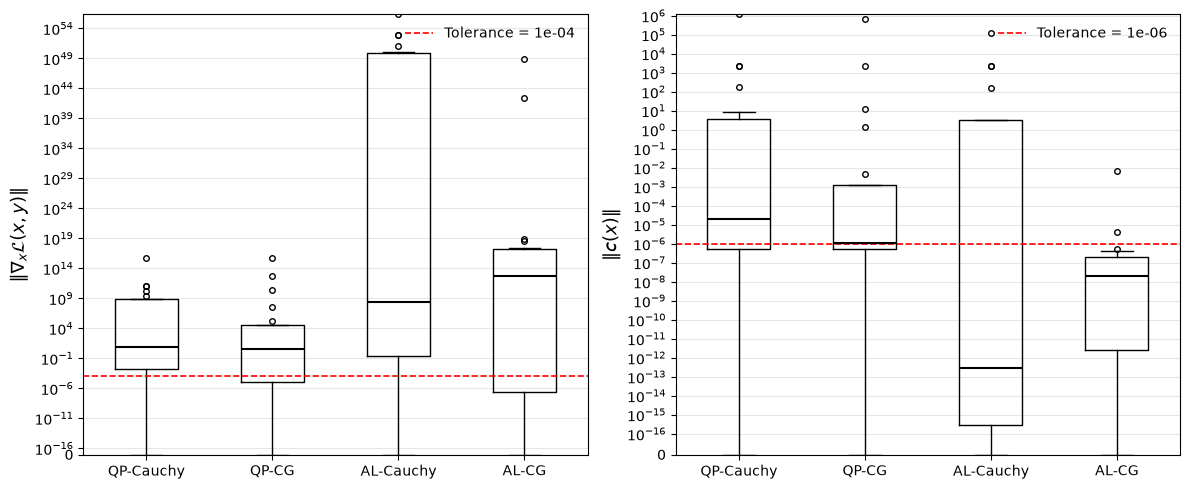

In [ ]:
import matplotlib.pyplot as plt

labels = ["QP-Cauchy", "QP-CG", "AL-Cauchy", "AL-CG"]

grad_data = [ng_qp_ca, ng_qp_cg, ng_al_ca, ng_al_cg]
constr_data = [nc_qp_ca, nc_qp_cg, nc_al_ca, nc_al_cg]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, data, ylabel, tol in zip(
    axes,
    [grad_data, constr_data],
    [r"$\|\nabla_x \mathcal{L}(x,y)\|$", r"$\|c(x)\|$"],
    [1e-4, 1e-6]
):
    ax.boxplot(
        data,
        widths=0.5,
        showfliers=True,
        boxprops=dict(color="black"),
        medianprops=dict(color="black", linewidth=1.5),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        flierprops=dict(
            marker="o",
            markerfacecolor="none",
            markeredgecolor="black",
            markersize=4,
            linestyle="none"
        )
    )

    ax.set_xticks([1, 2, 3, 4], labels)
    ax.set_ylabel(ylabel, fontsize=13)

    ax.set_yscale("symlog", linthresh=1e-16)
    ax.set_ylim(bottom=0)

    ax.axhline(
        tol, color="red", linestyle="--",
        linewidth=1.2, label=f"Tolerance = {tol:.0e}"
    )
    ax.legend(frameon=False)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
# Compute Performance Ratios

computations = np.column_stack([
    comp_qp_ca, comp_qp_cg, comp_al_ca, comp_al_cg
]).astype(float)

gradient_norms = np.column_stack([
    ng_qp_ca, ng_qp_cg, ng_al_ca, ng_al_cg
])

constraint_norms = np.column_stack([
    nc_qp_ca, nc_qp_cg, nc_al_ca, nc_al_cg
])

success = (
    (gradient_norms <= 1e-4)
    & (constraint_norms <= 1e-6)
)

cost = np.where(success, computations, np.inf)

best_cost = np.min(cost, axis=1)

ratios = np.full_like(cost, np.inf)
solved = np.isfinite(best_cost)
ratios[solved] = cost[solved] / best_cost[solved, None]

ratio_qp_ca = ratios[:, 0].copy()
ratio_qp_cg = ratios[:, 1].copy()
ratio_al_ca = ratios[:, 2].copy()
ratio_al_cg = ratios[:, 3].copy()


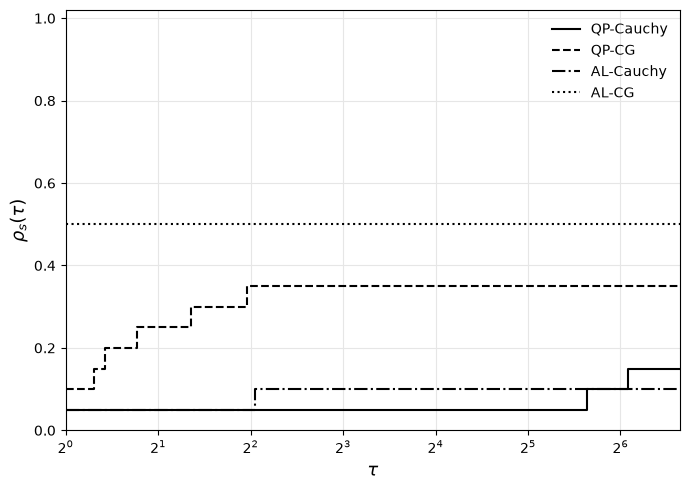

In [98]:
# Plot Performance Profiles

ratio_vectors = [
    ratio_qp_ca, ratio_qp_cg, ratio_al_ca, ratio_al_cg
]

labels = ["QP-Cauchy", "QP-CG", "AL-Cauchy", "AL-CG"]
linestyles = ["-", "--", "-.", ":"]

all_ratios = np.concatenate(ratio_vectors)
taus = np.unique(np.r_[
    1.0,
    all_ratios[(all_ratios >= 1) & (all_ratios <= 100)],
    100.0
])

fig, ax = plt.subplots(figsize=(7, 5))

for ratios, label, linestyle in zip(
    ratio_vectors, labels, linestyles
):
    profile = np.array([
        np.mean(ratios <= tau)
        for tau in taus
    ])

    ax.step(
        taus, profile,
        where="post",
        color="black",
        linestyle=linestyle,
        linewidth=1.5,
        label=label
    )

ax.set_xscale("log", base=2)
ax.set_xlim(1, 100)
ax.set_ylim(0, 1.02)

ax.set_xlabel(r"$\tau$", fontsize=13)
ax.set_ylabel(r"$\rho_s(\tau)$", fontsize=13)
ax.legend(frameon=False)
ax.grid(color="0.9")
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()